In [1]:
from fontTools.misc.intTools import bit_count

ip = [58, 50, 42, 34, 26, 18, 10, 2,
      60, 52, 44, 36, 28, 20, 12, 4,
      62, 54, 46, 38, 30, 22, 14, 6,
      64, 56, 48, 40, 32, 24, 16, 8,
      57, 49, 41, 33, 25, 17, 9, 1,
      59, 51, 43, 35, 27, 19, 11, 3,
      61, 53, 45, 37, 29, 21, 13, 5,
      63, 55, 47, 39, 31, 23, 15, 7]

ip_inv = [40, 8, 48, 16, 56, 24, 64, 32,
          39, 7, 47, 15, 55, 23, 63, 31,
          38, 6, 46, 14, 54, 22, 62, 30,
          37, 5, 45, 13, 53, 21, 61, 29,
          36, 4, 44, 12, 52, 20, 60, 28,
          35, 3, 43, 11, 51, 19, 59, 27,
          34, 2, 42, 10, 50, 18, 58, 26,
          33, 1, 41, 9, 49, 17, 57, 25]


e = [32, 1, 2, 3, 4, 5,
    4, 5, 6, 7, 8, 9,
    8, 9,  10, 11, 12, 13,
    12, 13, 14, 15, 16, 17,
    16, 17, 18, 19, 20, 21,
    20, 21, 22, 23, 24, 25,
    24, 25, 26, 27, 28, 29,
    28, 29, 30, 31, 32, 1]

s = [[14, 4, 13, 1, 2, 15, 11, 8, 3, 10, 6, 12, 5, 9, 0, 7,
      0, 15, 7, 4, 14, 2, 13, 1, 10, 6, 12, 11, 9, 5, 3, 8,
      4, 1, 14, 8, 13, 6, 2, 11, 15, 12, 9, 7, 3, 10, 5, 0,
     15, 12, 8, 2, 4, 9, 1, 7, 5, 11, 3, 14, 10, 0, 6, 13],
     [15, 1, 8, 14, 6, 11, 3, 4, 9, 7, 2, 13, 12, 0, 5, 10,
      3, 13, 4, 7, 15, 2, 8, 14, 12, 0, 1, 10, 6, 9, 11, 5,
      0, 14, 7, 11, 10, 4, 13, 1, 5, 8, 12, 6, 9, 3, 2, 15,
      13, 8, 10, 1, 3, 15, 4, 2, 11, 6, 7, 12, 0, 5, 14, 9],
     [10, 0, 9, 14, 6, 3, 15, 5, 1, 13, 12, 7, 11, 4, 2, 8,
      13, 7, 0, 9, 3, 4, 6, 10, 2, 8, 5, 14, 12, 11, 15, 1,
      13, 6, 4, 9, 8, 15, 3, 0, 11, 1, 2, 12, 5, 10, 14, 7,
      1, 10, 13, 0, 6, 9, 8, 7, 4, 15, 14, 3, 11, 5, 2, 12],
     [7, 13, 14, 3, 0, 6, 9, 10, 1, 2, 8, 5, 11, 12, 4, 15,
      13, 8, 11, 5, 6, 15, 0, 3, 4, 7, 2, 12, 1, 10, 14, 9,
      10, 6, 9, 0, 12, 11, 7, 13, 15, 1, 3, 14, 5, 2, 8, 4,
      3, 15, 0, 6, 10, 1, 13, 8, 9, 4, 5, 11, 12, 7, 2, 14],
     [2, 12, 4, 1, 7, 10, 11, 6, 8, 5, 3, 15, 13, 0, 14, 9,
      14, 11, 2, 12, 4, 7, 13, 1, 5, 0, 15, 10, 3, 9, 8, 6,
      4, 2, 1, 11, 10, 13, 7, 8, 15, 9, 12, 5, 6, 3, 0, 14,
      11, 8, 12, 7, 1, 14, 2, 13, 6, 15, 0, 9, 10, 4, 5, 3],
     [12, 1, 10, 15, 9, 2, 6, 8, 0, 13, 3, 4, 14, 7, 5, 11,
      10, 15, 4, 2, 7, 12, 9, 5, 6, 1, 13, 14, 0, 11, 3, 8,
      9, 14, 15, 5, 2, 8, 12, 3, 7, 0, 4, 10, 1, 13, 11, 6,
      4, 3, 2, 12, 9, 5, 15, 10, 11, 14, 1, 7, 6, 0, 8, 13],
     [4, 11, 2, 14, 15, 0, 8, 13, 3, 12, 9, 7, 5, 10, 6, 1,
      13, 0, 11, 7, 4, 9, 1, 10, 14, 3, 5, 12, 2, 15, 8, 6,
      1, 4, 11, 13, 12, 3, 7, 14, 10, 15, 6, 8, 0, 5, 9, 2,
      6, 11, 13, 8, 1, 4, 10, 7, 9, 5, 0, 15, 14, 2, 3, 12],
     [13, 2, 8, 4, 6, 15, 11, 1, 10, 9, 3, 14, 5, 0, 12, 7,
      1, 15, 13, 8, 10, 3, 7, 4, 12, 5, 6, 11, 0, 14, 9, 2,
      7, 11, 4, 1, 9, 12, 14, 2, 0, 6, 10, 13, 15, 3, 5, 8,
      2, 1, 14, 7, 4, 10, 8, 13, 15, 12, 9, 0, 3, 5, 6, 11]
     ]

p = [16, 7, 20, 21, 29, 12, 28, 17,
     1, 15, 23, 26, 5, 18, 31, 10,
     2, 8, 24, 14, 32, 27, 3, 9,
     19, 13, 30, 6, 22, 11, 4, 25]

def IP(num):
    result = 0
    for i in range(64):
        bit = (num >>  64 - ip[i]) & 1
        result = (result << 1 | bit)
    return result

def IPinv(num):
    result = 0
    for i in range(64):
        bit = (num >> 64 - ip_inv[i]) & 1
        result = (result << 1 | bit)
    return result


def E(R):
    result = 0
    for i in range(48):
        bit = (R >> 32 - e[i]) & 1
        result = (result << 1 | bit)
    return result

def S(num, i):
    a = num >> 5  << 1 | num & 1
    b = num >> 1 & 0xf
    return s[i][16 * a + b]

def P(R):
    result = 0
    for i in range(32):
        bit = (R >> 32 - p[i]) & 1
        result = (result << 1 | bit)
    return result



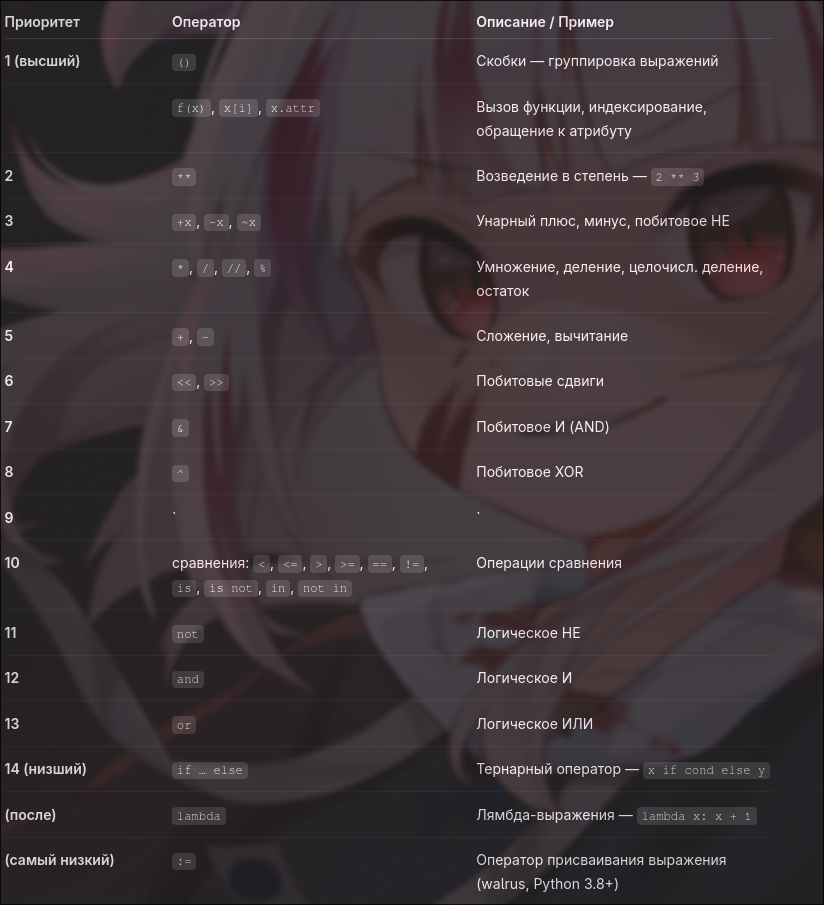

Развёртка ключа

In [2]:
pi = [57, 49, 41, 33, 25, 17, 9, 1, 58, 50, 42, 34, 26, 18,
      10, 2, 59, 51, 43, 35, 27, 19, 11, 3, 60, 52, 44, 36,
      63, 55, 47, 39, 31, 23, 15, 7, 62, 54, 46, 38, 30, 22,
      14, 6, 61, 53, 45, 37, 29, 21, 13, 5, 28, 20, 12, 4]

t = [14, 17, 11, 24, 1, 5, 3, 28,
     15, 6, 21, 10, 23, 19, 12, 4,
     26, 8, 16, 7, 27, 20, 13, 2,
     41, 52, 31, 37, 47, 55, 30, 40,
     51, 45, 33, 48, 44, 49, 39, 56,
     34, 53, 46, 42, 50, 36, 29, 32,
]

key_bit_shift = [1, 2, 4, 6, 8, 10, 12, 14, 15, 17, 19, 21, 23, 25, 27, 28]


def key_extend(key):
    # assert  48 < key.bit_length() <= 56
    result = 0
    for i in range(8):
        result <<= 8
        key_i = key >> 7 * (7 - i) & 0x7f
        result |= key_i << 1 | 1 ^ key_i.bit_count() & 1
    return result

def PI(key):
    C = 0
    for i in range(28):
        bit = (key >> 64 - pi[i]) & 1
        C = (C << 1 | bit)
    D = 0
    for i in range(28, 56):
        bit = (key >> 64 - pi[i]) & 1
        D = (D << 1 | bit)
    return C, D

def rot(value, shift):
    return  (value << shift | value >> 28 - shift) & 0xfffffff

def T(key):
    res = 0
    for i in range(48):
        bit = (key >> 56 - t[i]) & 1
        res = (res << 1 | bit)
    return res


def key_gen(key):
    # key = key_extend(key)
    C, D = PI(key)
    # res = []
    res = [T(rot(C, i) << 28 | rot(D, i)) for i in key_bit_shift]
    return res

In [16]:
from random import *
from Crypto.Util.number import *
def F(R, key):
    R = E(R)
    R = R ^ key

    res = 0
    for i in range(8):
        res <<= 4
        res |= S(R >> 6 * (7 - i) & 0x3f, i)
    return P(res)

def des_encrypt(text, key):
    text = int.from_bytes(text, 'big')
    keys = key_gen(key)
    text = IP(text)
    L, R = text >> 32, text & 0xffffffff
    for i in range(15):
        L, R =  R, F(R, keys[i]) ^ L

    L = F(R, keys[15]) ^ L
    ctext = L << 32 | R
    return  IPinv(ctext).to_bytes(8, 'big')


def des_decrypt(text, key):
    text = int.from_bytes(text, 'big')
    keys = key_gen(key)[::-1]
    text = IP(text)
    L, R = text >> 32, text & 0xffffffff
    for i in range(15):
        L, R =  R, F(R, keys[i]) ^ L

    L = F(R, keys[15]) ^ L
    ctext = L << 32 | R
    return  IPinv(ctext).to_bytes(8, 'big')

from Crypto.Util.number import bytes_to_long, long_to_bytes
# key = getrandbits(56)
key = 0xffeeddccbbaa9988
m = long_to_bytes(0xfedcba9876543210)
# print(hex(F(0x7ca663e4, 0xf2c6bb7e23f3)), 1)
c = long_to_bytes(0x4679cf5cf4270928)
print((des_encrypt(m, key)))
print((des_decrypt(c, key)))
# text = 0xfedcba9876543210
# print(hex(key_extend(key)))
# text = getrandbits(64)

# print(hex(text), text.bit_length())
# print(hex(des(text, key)))



b"Fy\xcf\\\xf4'\t("
b'\xfe\xdc\xba\x98vT2\x10'
